In [1]:
import torch
import torch.nn as nn

import brevitas.nn as qnn
from brevitas.nn import QuantLinear, QuantReLU, QuantConv2d
from brevitas.inject.enum import QuantType
from brevitas.quant_tensor.int_quant_tensor import IntQuantTensor
from brevitas.function.ops_ste import round_ste
from brevitas.quant import Int8WeightPerChannelFloat

from GRAUApproxToolkit import GRAU_Linear

In [2]:
# -------------------------------
# Basic configuration
# -------------------------------
torch.manual_seed(0)
device = "cpu"   

B = 4            # batch size
in_features = 16
out_features = 8

weight_bit_width = 8
act_bit_width = 8

In [3]:
# -------------------------------
# Build a minimal QNN block
# -------------------------------
linear = qnn.QuantLinear(
    in_features,
    out_features,
    weight_bit_width=weight_bit_width,
    weight_quant=Int8WeightPerChannelFloat,
    bias=False,
    return_quant_tensor=True,
)

bn = nn.BatchNorm1d(out_features)

act = qnn.QuantReLU(
    bit_width=act_bit_width,
    return_quant_tensor=True
)

linear.to(device)
bn.to(device)
act.to(device)

QuantReLU(
  (input_quant): ActQuantProxyFromInjector(
    (_zero_hw_sentinel): StatelessBuffer()
  )
  (act_quant): ActQuantProxyFromInjector(
    (_zero_hw_sentinel): StatelessBuffer()
    (fused_activation_quant_proxy): FusedActivationQuantProxy(
      (activation_impl): ReLU()
      (tensor_quant): RescalingIntQuant(
        (int_quant): IntQuant(
          (float_to_int_impl): RoundSte()
          (tensor_clamp_impl): TensorClamp()
          (delay_wrapper): DelayWrapper(
            (delay_impl): _NoDelay()
          )
          (input_view_impl): Identity()
        )
        (scaling_impl): ParameterFromRuntimeStatsScaling(
          (stats_input_view_shape_impl): OverTensorView()
          (stats): _Stats(
            (stats_impl): AbsPercentile()
          )
          (restrict_scaling_impl): FloatRestrictValue()
          (restrict_scaling): _RestrictValue(
            (restrict_value_impl): FloatRestrictValue()
          )
          (clamp_scaling): _ClampValue(
            

In [4]:
min_max_stats = (-500.0, 500.0)

In [5]:
grau = GRAU_Linear(
    linear_layer=linear,
    bn_layer=bn,
    act_layer=act,
    min_max_stats=min_max_stats,
    device=device,
    segment_num=6,       
    n_fit_points=1000,
    min_gap=1,
    pot_min_exp=-10,
    pot_max_exp=6,
)

/home/yuhao/anaconda3/envs/brevitas/lib/python3.9/site-packages/torch/_tensor.py:1362: UserWarning: Named tensors and all their associated APIs are an experimental feature and subject to change. Please do not use them for anything important until they are released as stable. (Triggered internally at /opt/conda/conda-bld/pytorch_1695392022560/work/c10/core/TensorImpl.h:1900.)
  return super().rename(names)


In [6]:
x = torch.randn(B, in_features, device=device) * 250.0
print(x)

tensor([[-220.8439, -104.7284, -201.2066,  141.4024,  152.5912,  116.7209,
          487.6643, -265.7746,  -19.3314,   29.0997, -148.4977, -310.9821,
          -25.5232, -258.3871,  -78.1597,   61.4464],
        [ -64.9104,   29.5843,   60.9898,  291.1501,   72.1440,   96.6494,
          -50.2660,  -29.4817,   48.0498, -193.0392, -475.0863,   32.6694,
         -176.0735,   78.6802,   39.3482,   96.3407],
        [ 241.7864, -247.7707,   75.4014,  -26.8292,  249.6142, -124.6787,
          190.2777,  154.5752,   78.5121,   53.3332,  -30.0127,   90.1149,
          -78.5088, -269.6770,   60.2026, -349.0568],
        [ -16.5360,  -89.5888, -390.3904,  -88.6608,  270.2681,   32.8695,
          393.3846,  195.3575, -269.6645, -180.2275,  367.6982,   68.9088,
          166.6953, -248.5974, -297.3410, -298.9874]])


In [7]:
x_in = IntQuantTensor(value = x, 
                             scale=1.0, 
                             zero_point=0.0, 
                             bit_width=8, 
                             signed=True, 
                             training=False)

In [8]:
x_q = linear(x_in)

/home/yuhao/anaconda3/envs/brevitas/lib/python3.9/site-packages/brevitas/nn/quant_linear.py:69: UserWarning: Defining your `__torch_function__` as a plain method is deprecated and will be an error in future, please define it as a classmethod. (Triggered internally at /opt/conda/conda-bld/pytorch_1695392022560/work/torch/csrc/utils/python_arg_parser.cpp:368.)
  output_tensor = linear(x, quant_weight, quant_bias)


In [9]:
y_pwlf = grau(x_in, "PWLF")
y_pot  = grau(x_in, "PoT-PWLF")
y_apot = grau(x_in, "APoT-PWLF")

print("PWLF output:\n", y_pwlf)
print("PoT-PWLF output:\n", y_pot)
print("APoT-PWLF output:\n", y_apot)

PWLF output:
 IntQuantTensor(value=tensor([[255., 255., 255., 255.,   0.,   0., 255.,   0.],
        [  0.,   0.,   0., 255.,   0.,   0., 255., 255.],
        [255.,   0.,   0.,   0., 255.,   0.,   0., 255.],
        [255., 255., 255.,   0., 255., 255., 255.,   0.]],
       grad_fn=<ClampBackward1>), scale=1.0, zero_point=0.0, bit_width=8.0, signed_t=False, training_t=False)
PoT-PWLF output:
 IntQuantTensor(value=tensor([[255., 255., 255., 255.,   0.,   0., 255.,   0.],
        [  0.,   0.,   0., 255.,   0.,   0., 255., 255.],
        [255.,   0.,   0.,   0., 255.,   0.,   0., 255.],
        [255., 255., 255.,   0., 255., 255., 255.,   0.]],
       grad_fn=<ClampBackward1>), scale=1.0, zero_point=0.0, bit_width=8.0, signed_t=False, training_t=False)
APoT-PWLF output:
 IntQuantTensor(value=tensor([[255., 255., 255., 255.,   0.,   0., 255.,   0.],
        [  0.,   0.,   0., 255.,   0.,   0., 255., 255.],
        [255.,   0.,   0.,   0., 255.,   0.,   0., 255.],
        [255., 255., 255.,

/home/yuhao/project/GRAU-Approx-Toolkit/src/GRAUApproxToolkit/grau_linear.py:410: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at /opt/conda/conda-bld/pytorch_1695392022560/work/aten/src/ATen/native/BucketizationUtils.h:32.)
  seg = torch.searchsorted(knots_x, xc, right=True) - 1


In [10]:
print("Min / Max PWLF:", y_pwlf.value.min().item(), y_pwlf.value.max().item())
print("Min / Max PoT :", y_pot.value.min().item(),  y_pot.value.max().item())
print("Min / Max APoT:", y_apot.value.min().item(), y_apot.value.max().item())

Min / Max PWLF: 0.0 255.0
Min / Max PoT : 0.0 255.0
Min / Max APoT: 0.0 255.0


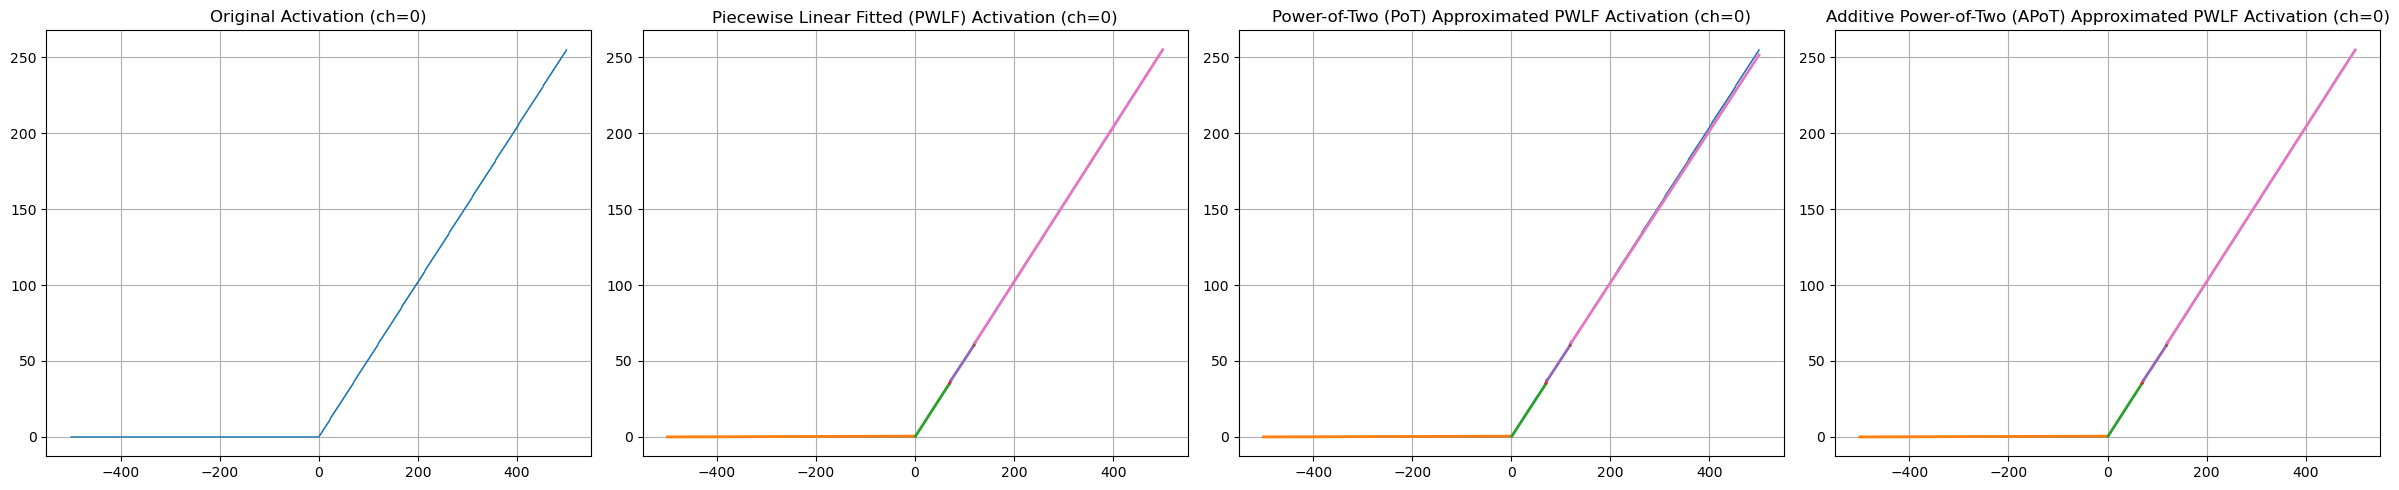

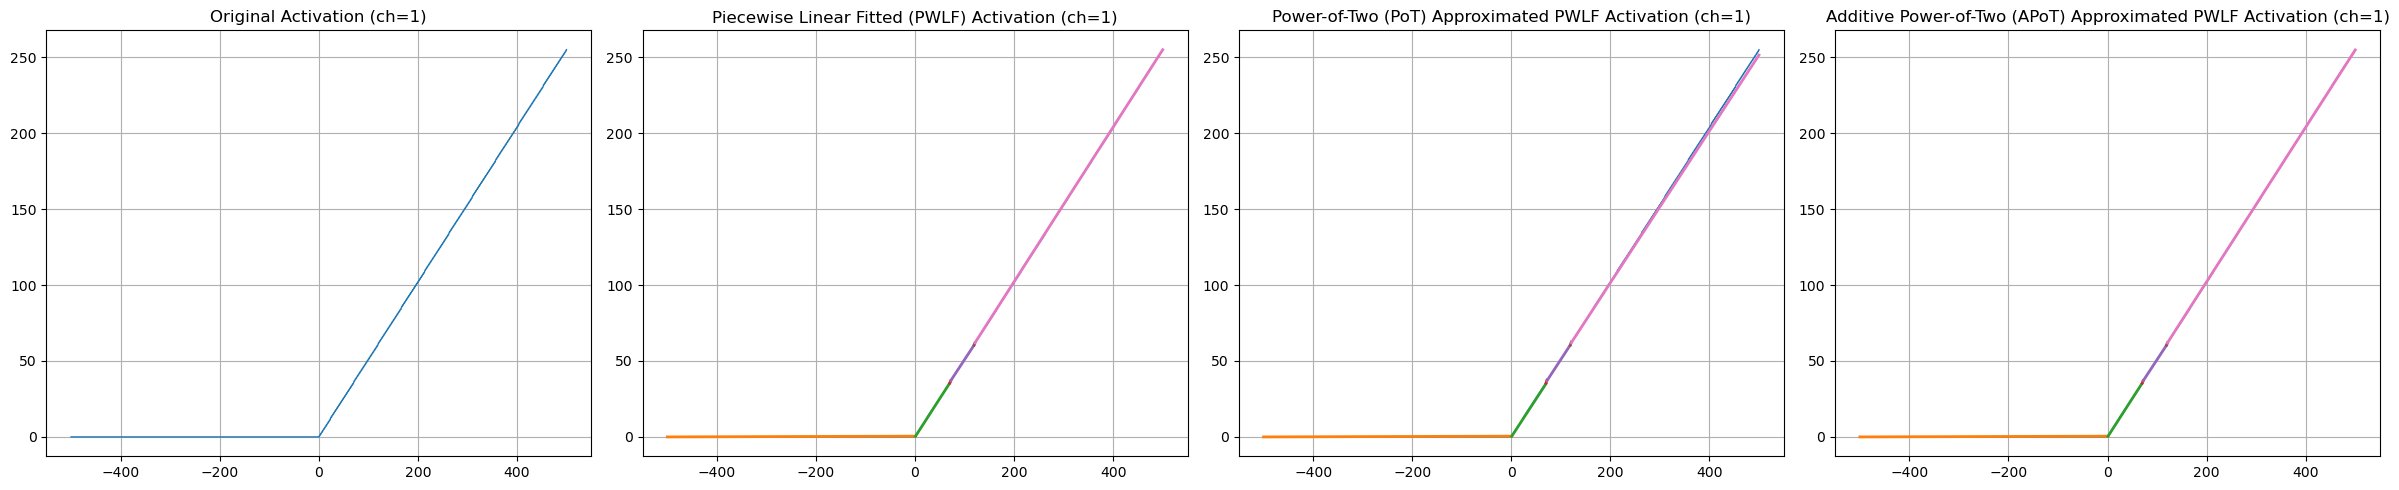

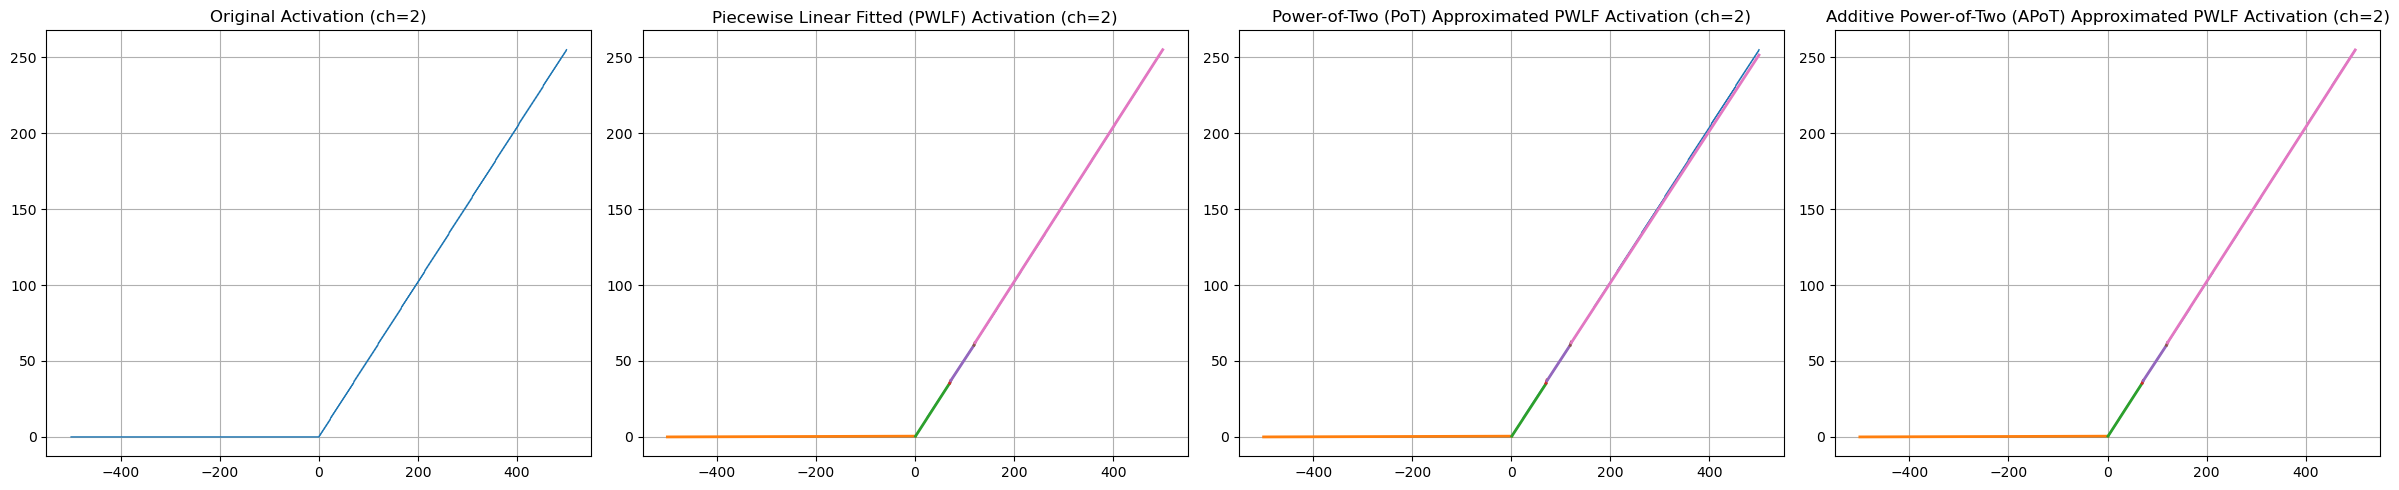

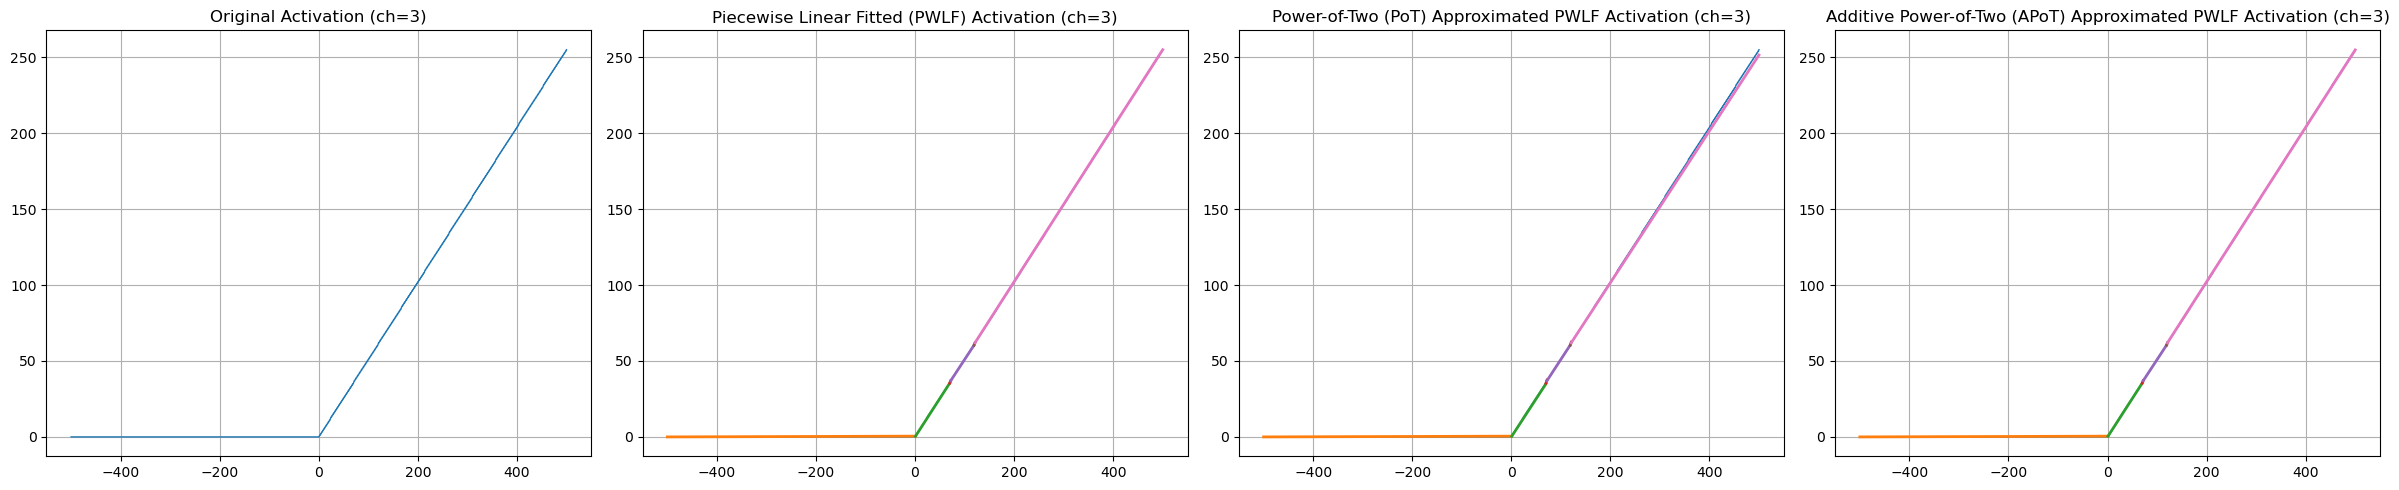

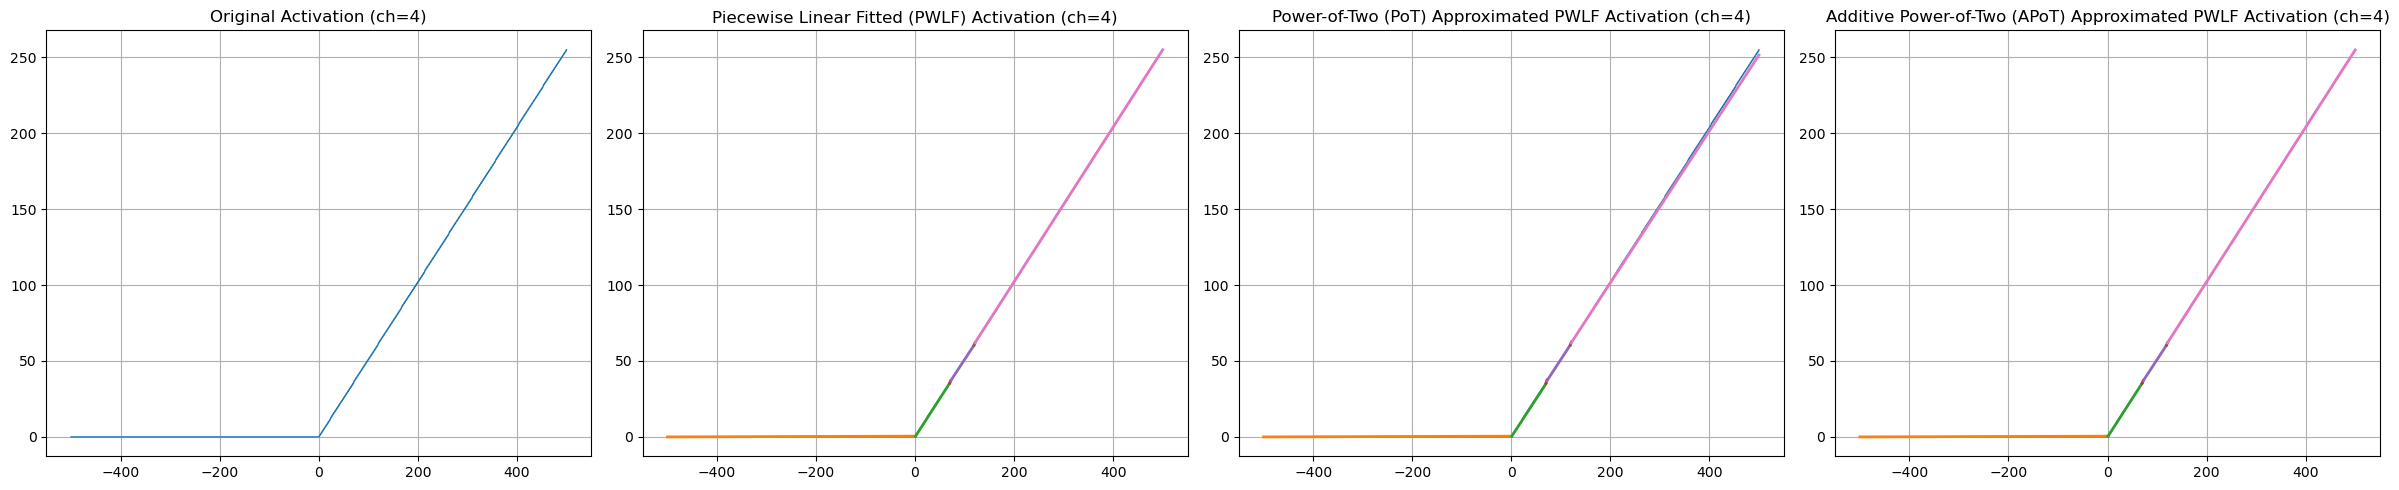

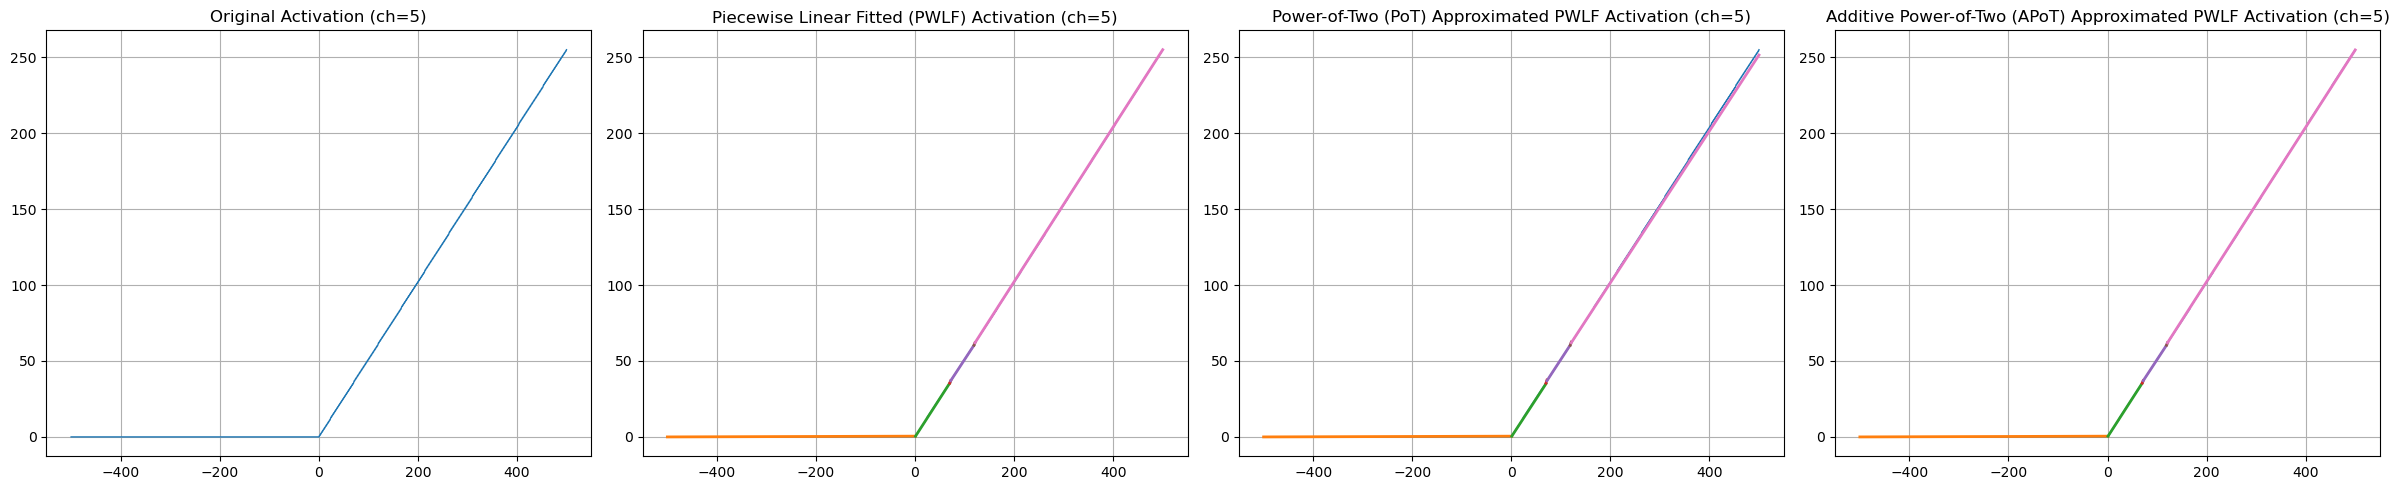

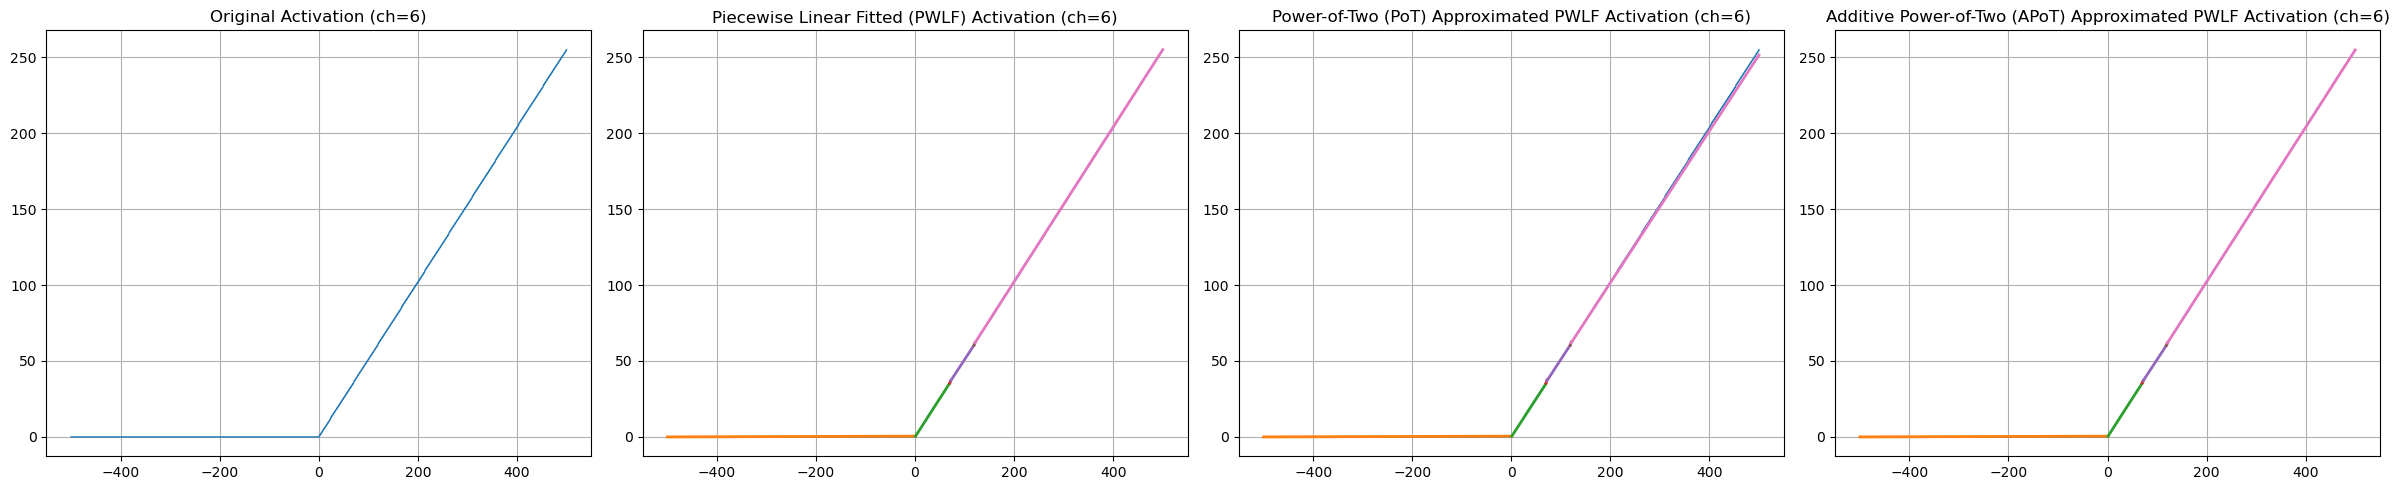

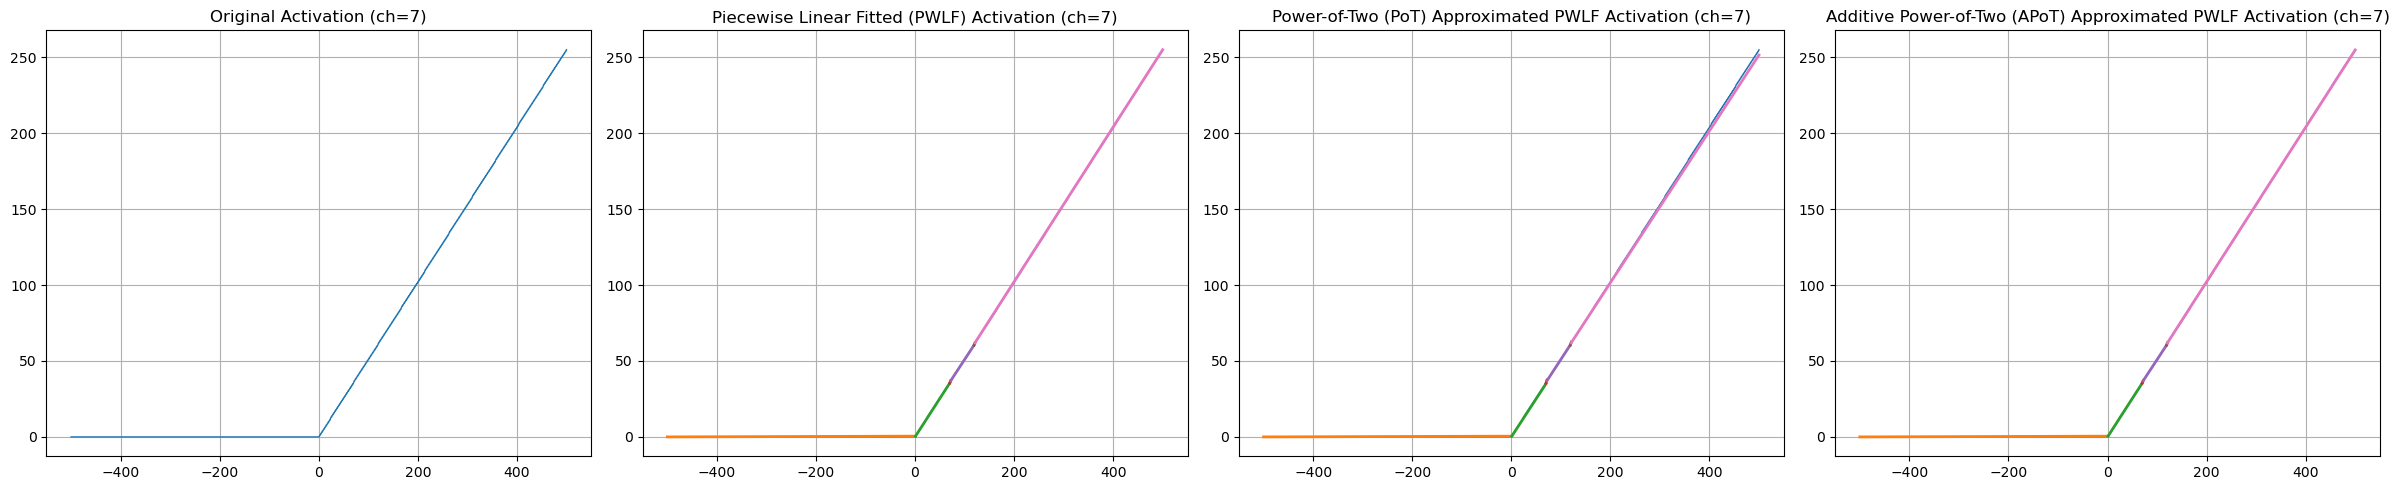

In [11]:
grau.plot_all_act()

In [12]:
grau.print_activation_pwlf_params()

[Activation] PWLF parameter dump: channels=8, target_segments=6
  Fit range: [-500.0, 500.0] | n_fit_points=1000
  PoT/APoT exp range: [-10, 6]
  Output clamp range: [0, 255] | source=dummy_act_output(bit_width+signed_t)
  (bit_width=8, signed=False)

--- Channel 0 ---
segment_num: 6
breakpoints (internal): [  1  70  72 119 121]
knots_x (with endpoints): [-500.    1.   70.   72.  119.  121.  500.]

slopes:
  PWLF      : [0.00099601 0.50624635 0.78500111 0.49746803 0.80950131 0.50923483]
  PoT-PWLF  : [9.765625e-04 5.000000e-01 1.000000e+00 5.000000e-01 1.000000e+00
 5.000000e-01]
  APoT-PWLF : [0.00097656 0.50585938 0.78417969 0.49707031 0.80957031 0.50878906]

PoT representation:
  PoT-INT   : [-10  -1   0  -1   0  -1]
  PoT-SIGN  : [1 1 1 1 1 1]

APoT representation:
  APoT-INT  : [list([-10]) list([-9, -8, -1]) list([-10, -9, -5, -2, -1])
 list([-10, -8, -7, -6, -5, -4, -3, -2])
 list([-10, -8, -7, -6, -5, -2, -1]) list([-10, -7, -1])]
  APoT-SIGN : [1 1 1 1 1 1]

--- Channel 1 ---
